In [56]:
import numpy as np
from tokenizers import Tokenizer
from collections import OrderedDict
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt
import sys
from pathlib import Path

root = Path.cwd().parent
sys.path.insert(0, str(root))

import Project1

In [57]:
dataset = load_dataset("cardiffnlp/tweet_eval", "stance_climate")

In [58]:
# feature representation

class Encoder:

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")

class BagOfWords(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer

    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        vector = np.zeros(len(self))
        for token_id in self.tokenizer.encode(x).ids:
            vector[token_id] += 1
        return vector

class TokenIndicator(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(self.tokenizer.encode(x).ids))

        # A 0 vector with the same length as the vocabulary except in positions corresponding 
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector

class tfidf(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        self.idf = self._compute_idf()

    def _compute_idf(self) -> 'np.array':
        num_documents = len(self.dataset)
        df = np.zeros(len(self.tokenizer.get_vocab()))

        for example in self.dataset:
            unique_token_ids = set(self.tokenizer.encode(example['text']).ids)
            for token_id in unique_token_ids:
                df[token_id] += 1

        idf = np.log((num_documents + 1) / (df + 1)) + 1
        return idf

    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        tf_vector = np.zeros(len(self))
        token_ids = self.tokenizer.encode(x).ids

        for token_id in token_ids:
            tf_vector[token_id] += 1

        if len(token_ids) > 0:
            tf_vector /= len(token_ids)

        tfidf_vector = tf_vector * self.idf
        return tfidf_vector

In [59]:
#tokenizer
vocab_size = 1000
min_frequency = 2
corpus = [text for text in dataset["train"]["text"]]
tokenizer = Project1.experiment.train_tokenizer(corpus, vocab_size, min_frequency)
token_indicator_encoder = TokenIndicator(tokenizer)

In [60]:
# cross-validation
my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []

for seed in my_seeds:  
    my_cross_validation_sets.append(
        Project1.experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(dataset["train"]["text"], dataset["train"]["label"])), 
            k=num_folds,
            seed=seed
        )
    )

In [61]:
results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True) 

In [62]:
# classifiers
logistic_model = Project1.loglin.fit(my_cross_validation_sets[0][0]["training"], token_indicator_encoder, save_to=None)



/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [63]:
outcome_space_abortion = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_atheism = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_climate = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_feminist = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_hillary = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])

In [64]:
classifiers = OrderedDict()

In [65]:
token_indicator_encoder = TokenIndicator(tokenizer)

In [66]:
classifiers['logistic_indicator-enc'] = []
for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
    run_folder = f"{results_folder}/logistic_indicator-enc/seed-{seed}"
    classifiers['logistic_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=token_indicator_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, catego

In [67]:
bow_encoder = BagOfWords(tokenizer)

classifiers['logistic_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_bow-enc/seed-{seed}"
    classifiers['logistic_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=bow_encoder,
            model_option='logistic',
            save_to=run_folder,
            loglin_args={'max_iter': 100}
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklear

In [68]:
classifiers['mlp_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp_indicator-enc/seed-{seed}"
    classifiers['mlp_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=token_indicator_encoder,
            model_option='mlp', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.070 seconds
Dataloader done! Time taken: 0.002 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0404 | train acc: 0.4718 | val loss: 1.0038 | val acc: 0.5070
Epoch 02 | train loss: 0.8873 | train acc: 0.7148 | val loss: 0.9562 | val acc: 0.4648
Epoch 03 | train loss: 0.7779 | train acc: 0.6937 | val loss: 0.9391 | val acc: 0.4648
Epoch 04 | train loss: 0.6760 | train acc: 0.7148 | val loss: 0.9288 | val acc: 0.4930
Epoch 05 | train loss: 0.6009 | train acc: 0.8134 | val loss: 0.9238 | val acc: 0.4648
Epoch 06 | train loss: 0.5336 | train acc: 0.9155 | val loss: 0.9227 | val acc: 0.5211
Epoch 07 | train loss: 0.4588 | train acc: 0.9507 | val loss: 0.9249 | val acc: 0.4930
Epoch 08 | train loss: 0.3963 | train acc: 0.9613 | val loss: 0.9289 | val acc: 0.5352
Epoch 09 | train loss: 0.3362 | train acc: 0.9613 | val loss: 0.9344 | val acc: 0.5352
Epoch 10 | train loss: 0.2848 | train acc: 0.9648 | val loss: 0.9400 | val acc: 0.5352
Epoch 11 | train loss: 0.2365 | train acc: 0.9754 | val loss: 0.9511 | val acc: 0.5211
Epoch 12 | train loss: 0.1947 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0597 | train acc: 0.4789 | val loss: 0.9350 | val acc: 0.7042
Epoch 02 | train loss: 0.9188 | train acc: 0.5986 | val loss: 0.8403 | val acc: 0.7042
Epoch 03 | train loss: 0.8077 | train acc: 0.6831 | val loss: 0.7724 | val acc: 0.7606
Epoch 04 | train loss: 0.7127 | train acc: 0.8099 | val loss: 0.7244 | val acc: 0.7746
Epoch 05 | train loss: 0.6309 | train acc: 0.8803 | val loss: 0.6939 | val acc: 0.7606
Epoch 06 | train loss: 0.5557 | train acc: 0.9190 | val loss: 0.6681 | val acc: 0.7606
Epoch 07 | train loss: 0.4865 | train acc: 0.9366 | val loss: 0.6472 | val acc: 0.7606
Epoch 08 | train loss: 0.4207 | train acc: 0.9437 | val loss: 0.6337 | val acc: 0.7042
Epoch 09 | train loss: 0.3601 | train acc: 0.9542 | val loss: 0.6306 | val acc: 0.7042
Epoch 10 | train loss: 0.3043 | train acc: 0.9613 | val loss: 0.6327 | val acc: 0.6479
Epoch 11 | train loss: 0.2540 | train acc: 0.9613 | val loss: 0.6187 | val acc: 0.6901
Epoch 12 | train loss: 0.2146 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0544 | train acc: 0.4824 | val loss: 0.9828 | val acc: 0.5775
Epoch 02 | train loss: 0.9094 | train acc: 0.6901 | val loss: 0.8981 | val acc: 0.5634
Epoch 03 | train loss: 0.8007 | train acc: 0.7289 | val loss: 0.8354 | val acc: 0.5493
Epoch 04 | train loss: 0.7085 | train acc: 0.7394 | val loss: 0.7944 | val acc: 0.5493
Epoch 05 | train loss: 0.6239 | train acc: 0.7923 | val loss: 0.7645 | val acc: 0.5775
Epoch 06 | train loss: 0.5547 | train acc: 0.8662 | val loss: 0.7336 | val acc: 0.6338
Epoch 07 | train loss: 0.4809 | train acc: 0.9401 | val loss: 0.7063 | val acc: 0.6761
Epoch 08 | train loss: 0.4184 | train acc: 0.9542 | val loss: 0.6839 | val acc: 0.7324
Epoch 09 | train loss: 0.3577 | train acc: 0.9683 | val loss: 0.6658 | val acc: 0.7324
Epoch 10 | train loss: 0.3062 | train acc: 0.9577 | val loss: 0.6527 | val acc: 0.7606
Epoch 11 | train loss: 0.2546 | train acc: 0.9683 | val loss: 0.6422 | val acc: 0.7746
Epoch 12 | train loss: 0.2175 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0673 | train acc: 0.4190 | val loss: 0.9773 | val acc: 0.6056
Epoch 02 | train loss: 0.9301 | train acc: 0.6937 | val loss: 0.8768 | val acc: 0.5915
Epoch 03 | train loss: 0.8250 | train acc: 0.6972 | val loss: 0.8034 | val acc: 0.5775
Epoch 04 | train loss: 0.7431 | train acc: 0.7007 | val loss: 0.7508 | val acc: 0.6056
Epoch 05 | train loss: 0.6725 | train acc: 0.7430 | val loss: 0.7138 | val acc: 0.5915
Epoch 06 | train loss: 0.6029 | train acc: 0.8169 | val loss: 0.6868 | val acc: 0.5915
Epoch 07 | train loss: 0.5426 | train acc: 0.8838 | val loss: 0.6620 | val acc: 0.6056
Epoch 08 | train loss: 0.4707 | train acc: 0.9577 | val loss: 0.6449 | val acc: 0.6056
Epoch 09 | train loss: 0.4069 | train acc: 0.9542 | val loss: 0.6326 | val acc: 0.6197
Epoch 10 | train loss: 0.3440 | train acc: 0.9613 | val loss: 0.6242 | val acc: 0.6197
Epoch 11 | train loss: 0.2850 | train acc: 0.9613 | val loss: 0.6222 | val acc: 0.6479
Epoch 12 | train loss: 0.2361 | train acc: 

In [69]:
classifiers['mlp_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/mlp_bow-enc/seed-{seed}"
    classifiers['mlp_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=bow_encoder,
            model_option='mlp',
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.085 seconds
Dataloader done! Time taken: 0.002 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0366 | train acc: 0.5106 | val loss: 1.0160 | val acc: 0.4366
Epoch 02 | train loss: 0.8776 | train acc: 0.6585 | val loss: 0.9644 | val acc: 0.4085
Epoch 03 | train loss: 0.7645 | train acc: 0.7042 | val loss: 0.9390 | val acc: 0.4507
Epoch 04 | train loss: 0.6689 | train acc: 0.7570 | val loss: 0.9332 | val acc: 0.4648
Epoch 05 | train loss: 0.5884 | train acc: 0.8380 | val loss: 0.9317 | val acc: 0.4930
Epoch 06 | train loss: 0.5151 | train acc: 0.8838 | val loss: 0.9304 | val acc: 0.5070
Epoch 07 | train loss: 0.4456 | train acc: 0.9401 | val loss: 0.9279 | val acc: 0.5211
Epoch 08 | train loss: 0.3804 | train acc: 0.9507 | val loss: 0.9263 | val acc: 0.5634
Epoch 09 | train loss: 0.3154 | train acc: 0.9648 | val loss: 0.9265 | val acc: 0.5915
Epoch 10 | train loss: 0.2635 | train acc: 0.9648 | val loss: 0.9256 | val acc: 0.6056
Epoch 11 | train loss: 0.2192 | train acc: 0.9683 | val loss: 0.9312 | val acc: 0.6056
Epoch 12 | train loss: 0.1779 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.1148 | train acc: 0.2430 | val loss: 1.0132 | val acc: 0.5915
Epoch 02 | train loss: 0.9568 | train acc: 0.7077 | val loss: 0.8995 | val acc: 0.6761
Epoch 03 | train loss: 0.8426 | train acc: 0.7359 | val loss: 0.8141 | val acc: 0.6901
Epoch 04 | train loss: 0.7529 | train acc: 0.7711 | val loss: 0.7608 | val acc: 0.7042
Epoch 05 | train loss: 0.6687 | train acc: 0.8873 | val loss: 0.7256 | val acc: 0.7324
Epoch 06 | train loss: 0.5956 | train acc: 0.9296 | val loss: 0.6993 | val acc: 0.7465
Epoch 07 | train loss: 0.5262 | train acc: 0.9437 | val loss: 0.6828 | val acc: 0.7324
Epoch 08 | train loss: 0.4552 | train acc: 0.9507 | val loss: 0.6613 | val acc: 0.7324
Epoch 09 | train loss: 0.3952 | train acc: 0.9472 | val loss: 0.6469 | val acc: 0.7042
Epoch 10 | train loss: 0.3345 | train acc: 0.9577 | val loss: 0.6388 | val acc: 0.7042
Epoch 11 | train loss: 0.2809 | train acc: 0.9577 | val loss: 0.6466 | val acc: 0.7183
Epoch 12 | train loss: 0.2396 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0480 | train acc: 0.4683 | val loss: 0.9795 | val acc: 0.4789
Epoch 02 | train loss: 0.9095 | train acc: 0.7359 | val loss: 0.8943 | val acc: 0.6056
Epoch 03 | train loss: 0.8041 | train acc: 0.8275 | val loss: 0.8313 | val acc: 0.5915
Epoch 04 | train loss: 0.7179 | train acc: 0.8451 | val loss: 0.7902 | val acc: 0.6338
Epoch 05 | train loss: 0.6387 | train acc: 0.8768 | val loss: 0.7611 | val acc: 0.6479
Epoch 06 | train loss: 0.5654 | train acc: 0.8979 | val loss: 0.7367 | val acc: 0.6479
Epoch 07 | train loss: 0.4982 | train acc: 0.9190 | val loss: 0.7114 | val acc: 0.6901
Epoch 08 | train loss: 0.4293 | train acc: 0.9366 | val loss: 0.6861 | val acc: 0.7465
Epoch 09 | train loss: 0.3723 | train acc: 0.9507 | val loss: 0.6659 | val acc: 0.7465
Epoch 10 | train loss: 0.3163 | train acc: 0.9577 | val loss: 0.6525 | val acc: 0.7465
Epoch 11 | train loss: 0.2646 | train acc: 0.9577 | val loss: 0.6453 | val acc: 0.7465
Epoch 12 | train loss: 0.2242 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0773 | train acc: 0.3908 | val loss: 0.9901 | val acc: 0.5493
Epoch 02 | train loss: 0.9165 | train acc: 0.6338 | val loss: 0.8884 | val acc: 0.5775
Epoch 03 | train loss: 0.8077 | train acc: 0.7183 | val loss: 0.8111 | val acc: 0.5775
Epoch 04 | train loss: 0.7118 | train acc: 0.7570 | val loss: 0.7573 | val acc: 0.5775
Epoch 05 | train loss: 0.6423 | train acc: 0.7993 | val loss: 0.7162 | val acc: 0.5915
Epoch 06 | train loss: 0.5695 | train acc: 0.8345 | val loss: 0.6827 | val acc: 0.6197
Epoch 07 | train loss: 0.4935 | train acc: 0.9049 | val loss: 0.6564 | val acc: 0.6338
Epoch 08 | train loss: 0.4341 | train acc: 0.9366 | val loss: 0.6392 | val acc: 0.6620
Epoch 09 | train loss: 0.3685 | train acc: 0.9401 | val loss: 0.6245 | val acc: 0.6338
Epoch 10 | train loss: 0.3159 | train acc: 0.9542 | val loss: 0.6147 | val acc: 0.6479
Epoch 11 | train loss: 0.2634 | train acc: 0.9577 | val loss: 0.6091 | val acc: 0.6901
Epoch 12 | train loss: 0.2203 | train acc: 

In [70]:
classifiers['logistic_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_tfidf-enc/seed-{seed}"
    classifiers['logistic_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=token_indicator_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, catego

In [71]:
classifiers['mlp_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/mlp_tfidf-enc/seed-{seed}"
    classifiers['mlp_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=token_indicator_encoder,
            model_option='mlp', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.073 seconds
Dataloader done! Time taken: 0.003 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0654 | train acc: 0.4331 | val loss: 1.0195 | val acc: 0.5211
Epoch 02 | train loss: 0.9075 | train acc: 0.6937 | val loss: 0.9680 | val acc: 0.4930
Epoch 03 | train loss: 0.7852 | train acc: 0.7570 | val loss: 0.9401 | val acc: 0.4648
Epoch 04 | train loss: 0.6892 | train acc: 0.7746 | val loss: 0.9335 | val acc: 0.4648
Epoch 05 | train loss: 0.6043 | train acc: 0.8239 | val loss: 0.9358 | val acc: 0.4930
Epoch 06 | train loss: 0.5305 | train acc: 0.8838 | val loss: 0.9330 | val acc: 0.4789
Epoch 07 | train loss: 0.4576 | train acc: 0.9401 | val loss: 0.9285 | val acc: 0.5352
Epoch 08 | train loss: 0.3935 | train acc: 0.9613 | val loss: 0.9320 | val acc: 0.5493
Epoch 09 | train loss: 0.3328 | train acc: 0.9613 | val loss: 0.9357 | val acc: 0.5493
Epoch 10 | train loss: 0.2768 | train acc: 0.9648 | val loss: 0.9408 | val acc: 0.5493
Epoch 11 | train loss: 0.2328 | train acc: 0.9683 | val loss: 0.9450 | val acc: 0.5493
Epoch 12 | train loss: 0.1950 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0260 | train acc: 0.4859 | val loss: 0.9176 | val acc: 0.7606
Epoch 02 | train loss: 0.8883 | train acc: 0.6655 | val loss: 0.8364 | val acc: 0.7606
Epoch 03 | train loss: 0.7883 | train acc: 0.7923 | val loss: 0.7726 | val acc: 0.7606
Epoch 04 | train loss: 0.6993 | train acc: 0.8873 | val loss: 0.7296 | val acc: 0.7465
Epoch 05 | train loss: 0.6173 | train acc: 0.9120 | val loss: 0.6913 | val acc: 0.7606
Epoch 06 | train loss: 0.5394 | train acc: 0.9296 | val loss: 0.6630 | val acc: 0.7465
Epoch 07 | train loss: 0.4680 | train acc: 0.9366 | val loss: 0.6451 | val acc: 0.7042
Epoch 08 | train loss: 0.4048 | train acc: 0.9472 | val loss: 0.6379 | val acc: 0.6620
Epoch 09 | train loss: 0.3403 | train acc: 0.9577 | val loss: 0.6319 | val acc: 0.6761
Epoch 10 | train loss: 0.2872 | train acc: 0.9577 | val loss: 0.6276 | val acc: 0.6761
Epoch 11 | train loss: 0.2387 | train acc: 0.9577 | val loss: 0.6181 | val acc: 0.6761
Epoch 12 | train loss: 0.2001 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0344 | train acc: 0.5070 | val loss: 0.9679 | val acc: 0.5493
Epoch 02 | train loss: 0.8984 | train acc: 0.5563 | val loss: 0.8928 | val acc: 0.5493
Epoch 03 | train loss: 0.8009 | train acc: 0.5810 | val loss: 0.8360 | val acc: 0.5493
Epoch 04 | train loss: 0.7166 | train acc: 0.6549 | val loss: 0.7963 | val acc: 0.5634
Epoch 05 | train loss: 0.6341 | train acc: 0.7923 | val loss: 0.7639 | val acc: 0.6197
Epoch 06 | train loss: 0.5652 | train acc: 0.8979 | val loss: 0.7351 | val acc: 0.6761
Epoch 07 | train loss: 0.4931 | train acc: 0.9401 | val loss: 0.7095 | val acc: 0.6901
Epoch 08 | train loss: 0.4256 | train acc: 0.9542 | val loss: 0.6863 | val acc: 0.7324
Epoch 09 | train loss: 0.3626 | train acc: 0.9683 | val loss: 0.6655 | val acc: 0.7465
Epoch 10 | train loss: 0.3091 | train acc: 0.9648 | val loss: 0.6482 | val acc: 0.7465
Epoch 11 | train loss: 0.2568 | train acc: 0.9718 | val loss: 0.6366 | val acc: 0.7465
Epoch 12 | train loss: 0.2146 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0505 | train acc: 0.5141 | val loss: 0.9690 | val acc: 0.6056
Epoch 02 | train loss: 0.9160 | train acc: 0.7077 | val loss: 0.8794 | val acc: 0.5915
Epoch 03 | train loss: 0.8064 | train acc: 0.7676 | val loss: 0.8087 | val acc: 0.6056
Epoch 04 | train loss: 0.7145 | train acc: 0.7746 | val loss: 0.7556 | val acc: 0.5915
Epoch 05 | train loss: 0.6402 | train acc: 0.8134 | val loss: 0.7144 | val acc: 0.5915
Epoch 06 | train loss: 0.5697 | train acc: 0.8627 | val loss: 0.6833 | val acc: 0.6338
Epoch 07 | train loss: 0.4998 | train acc: 0.9261 | val loss: 0.6567 | val acc: 0.6620
Epoch 08 | train loss: 0.4332 | train acc: 0.9472 | val loss: 0.6378 | val acc: 0.6761
Epoch 09 | train loss: 0.3693 | train acc: 0.9542 | val loss: 0.6245 | val acc: 0.6901
Epoch 10 | train loss: 0.3100 | train acc: 0.9472 | val loss: 0.6160 | val acc: 0.7042
Epoch 11 | train loss: 0.2594 | train acc: 0.9577 | val loss: 0.6112 | val acc: 0.7042
Epoch 12 | train loss: 0.2117 | train acc: 

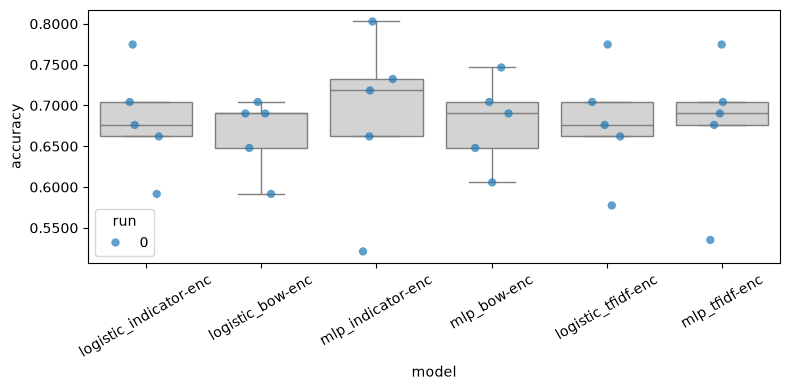

In [72]:
Project1.analysis.plot_box_and_points(Project1.analysis.make_data_frame(classifiers))